# Forecasting Penjualan Mobil Bulanan Indonesia (v2)
Daihatsu · Honda · Mitsubishi · Suzuki · Toyota — data Jan 2021 s.d. Jul 2025

Alurnya: **audit data → eksperimen dengan validasi rolling-origin → hasil → kesimpulan**.
Semua angka di notebook ini dihasilkan oleh sel yang dijalankan; tidak ada skor yang ditulis manual.

**Daftar isi:** 1 Konfigurasi · 2 Memuat data · 3 Audit data · 4 Audit pendekatan lama · 5 Fitur dan harness evaluasi · 6 Eksperimen dan uji kebocoran · 7 Hasil dan pemeriksaan konsistensi · 8 Prakiraan dan kalibrasi interval · 9 Keterbatasan · 10 Kesimpulan

## 1. Konfigurasi

In [19]:
import os, io, warnings
from urllib.request import urlopen
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from lightgbm import LGBMRegressor
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
warnings.filterwarnings('ignore')
SEED = 404; np.random.seed(SEED)

# ====== KONFIGURASI DATA ======
BASE_URL = os.environ.get("CARSALES_DATA_BASE",
                          "https://raw.githubusercontent.com/Rashifalmas/Pedas2025/main/data")
FILES = {
    "sales": "car_sales_2021_2025.csv",
    "bi":    "bi_7day_rr.xlsx",
    "ihk":   "inflasi_ihk_ytd_2022_100.csv",
}
SAVE_DIR = os.environ.get("CARSALES_SAVE_DIR")
# ====== PARAMETER EKSPERIMEN ======
BRANDS = ['DAIHATSU', 'HONDA', 'MITSUBISHI', 'SUZUKI', 'TOYOTA']
BREAK  = '2024-01-01'
TEST_A = ('2023-01-01', '2023-11-01')   # periode uji pra-patahan
TEST_B = ('2024-08-01', '2025-07-01')   # periode uji pasca-patahan (12 bulan terakhir)
BASE_WIN, BI_LAG, IHK_LAG = 3, 1, 2     # jendela level, lag BI (bulan), lag IHK (bulan)

## 2. Memuat data

In [20]:
BULAN = {'Januari':1,'Februari':2,'Maret':3,'April':4,'Mei':5,'Juni':6,'Juli':7,'Agustus':8,
         'September':9,'Oktober':10,'November':11,'Desember':12}

def url_of(key):
    if '<' in BASE_URL:
        raise ValueError("BASE_URL masih placeholder. Isi USERNAME/REPO/BRANCH di sel konfigurasi.")
    return BASE_URL.rstrip('/') + '/' + FILES[key]
def fetch(url): return io.BytesIO(urlopen(url).read())

def load_sales():
    s = pd.read_csv(fetch(url_of('sales')), parse_dates=['waktu']).set_index('waktu').sort_index()
    s_raw = s.copy()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='MS')); s.index.name = 'waktu'
    return s_raw[BRANDS], s[BRANDS]            # (apa adanya, dengan bulan hilang dibuat eksplisit = NaN)

def load_bi():
    raw = pd.read_excel(fetch(url_of('bi')), header=None)
    r = raw.index[raw.iloc[:, 1].astype(str).str.strip().eq('Tanggal')][0]
    d = raw.iloc[r+1:, [1, 2]].dropna(); d.columns = ['tgl', 'bi']
    p = d.tgl.str.split(expand=True)
    d['tanggal'] = pd.to_datetime(dict(year=p[2].astype(int), month=p[1].map(BULAN), day=p[0].astype(int)))
    d['bi'] = d.bi.astype(str).str.replace('%', '').str.strip().astype(float)
    m = d.set_index('tanggal').sort_index()['bi']
    n_rapat = m.groupby(m.index.to_period('M')).size()
    m = m.resample('MS').last(); m.index.name = 'waktu'      # level akhir bulan (rapat RDG = 1x/bulan)
    return m.rename('BI_RATE'), n_rapat

def load_ihk():
    raw = pd.read_csv(fetch(url_of('ihk')), skiprows=2, nrows=12, encoding='utf-8-sig')
    l = raw.melt(id_vars='Bulan', var_name='tahun', value_name='ytd').dropna()
    l['waktu'] = pd.to_datetime(dict(year=l.tahun.astype(int), month=l.Bulan.map(BULAN), day=1))
    ytd = l.set_index('waktu')['ytd'].astype(float).sort_index()
    idx = 1 + ytd/100; prev = idx.shift(1); prev[prev.index.month == 1] = 1.0   # YTD = perubahan vs Des tahun lalu
    return pd.DataFrame({'IHK_YTD': ytd, 'IHK_MOM': ((idx/prev) - 1)*100})      # MOM = inflasi bulanan

sales_raw, sales = load_sales()
bi, bi_rapat = load_bi()
ihk = load_ihk()
print('sales', sales_raw.shape, '| BI', bi.shape, '| IHK', ihk.shape)

sales (54, 5) | BI (55,) | IHK (235, 2)


## 3. Audit data

In [21]:
print('Rentang :', sales_raw.index.min().date(), '-', sales_raw.index.max().date(), '| baris:', len(sales_raw))
print('Duplikat baris/tanggal:', sales_raw.duplicated().sum(), '/', sales_raw.index.duplicated().sum())
print('Missing nilai (sebelum reindex):', int(sales_raw.isna().sum().sum()))
print('Bulan hilang dari deret:', [d.strftime('%Y-%m') for d in sales.index[sales.isna().all(axis=1)]])
print('BI  : bulan tanpa data =', int(bi.reindex(sales.index).isna().sum()), '| rapat/bulan (min,maks) =', (bi_rapat.min(), bi_rapat.max()))
print('IHK : bulan tanpa data =', int(ihk.reindex(sales.index).IHK_MOM.isna().sum()))
frac = (sales_raw % 1 != 0).groupby(sales_raw.index.year).mean().round(2)
print('\nProporsi nilai pecahan (non-integer) per tahun:'); print(frac)
a = sales_raw['2023-06-01':'2023-11-01'].mean(); c = sales_raw['2024-01-01':'2024-06-01'].mean()
print('\nRata-rata Jan-Jun 2024 dibanding Jun-Nov 2023:'); print((c/a).round(2).to_string())

Rentang : 2021-01-01 - 2025-07-01 | baris: 54
Duplikat baris/tanggal: 0 / 0
Missing nilai (sebelum reindex): 0
Bulan hilang dari deret: ['2023-12']
BI  : bulan tanpa data = 0 | rapat/bulan (min,maks) = (1, 1)
IHK : bulan tanpa data = 0

Proporsi nilai pecahan (non-integer) per tahun:
       DAIHATSU  HONDA  MITSUBISHI  SUZUKI  TOYOTA
waktu                                             
2021        0.0   0.00        0.00     0.0     0.0
2022        0.0   0.00        0.00     0.0     0.0
2023        0.0   0.00        0.00     0.0     0.0
2024        1.0   0.75        0.58     0.0     1.0
2025        1.0   0.86        0.29     1.0     1.0

Rata-rata Jan-Jun 2024 dibanding Jun-Nov 2023:
DAIHATSU      0.83
HONDA         0.37
MITSUBISHI    0.71
SUZUKI        0.47
TOYOTA        0.46


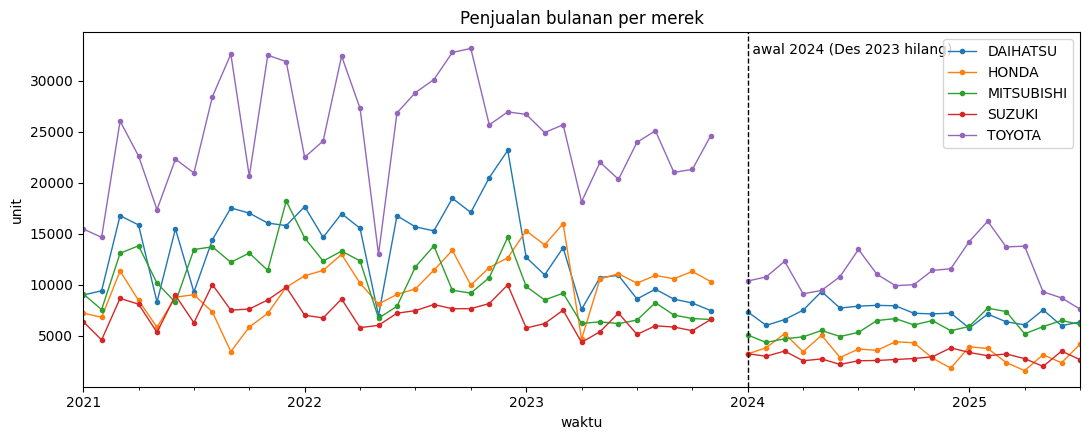

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sales.plot(ax=ax, marker='.', lw=1)
ax.axvline(pd.Timestamp(BREAK), color='k', ls='--', lw=1); ax.text(pd.Timestamp(BREAK), ax.get_ylim()[1]*0.97, ' awal 2024 (Des 2023 hilang)', va='top')
ax.set_title('Penjualan bulanan per merek'); ax.set_ylabel('unit'); plt.tight_layout(); plt.show()

**Temuan audit data** (angka di atas):
- Des 2023 **hilang** dari deret; menghitung `shift`/`rolling` berbasis baris tanpa menyisipkan bulan itu akan menggeser lag satu bulan. Pada notebook lama ini tidak berdampak karena hanya 2024–2025 yang dipakai, tetapi akan salah begitu data 2021–2023 dipakai.
- Terdapat **patahan level** di awal 2024 pada Honda, Toyota, Suzuki, Mitsubishi (rata-rata turun jauh), sedangkan Daihatsu relatif lebih landai. Nilai 2021–2023 seluruhnya bilangan bulat, sementara nilai 2024–2025 banyak yang pecahan.
- Konsekuensi desain: deret dibagi dua *rezim* (sebelum dan sejak Jan 2024). Semua statistik level pada eksperimen dihitung **di dalam rezim**, tidak melewati patahan.

## 4. Audit pendekatan lama (direproduksi, bukan diasumsikan)

Beberapa klaim audit diperiksa langsung:
1. **Ukuran data latih efektif.** Notebook lama memakai 2024–2025 dan membuang baris tanpa `lag_6`.
2. **Apakah model LightGBM hasil Optuna benar-benar memakai fitur?** Hiperparameter terbaik per merek diambil dari output tersimpan notebook lama.
3. **Kebocoran target pada fitur rolling** (tidak digeser sebelum dipakai).
4. **Stacking:** baris OOF yang tidak pernah diprediksi terisi nol lalu ikut melatih meta-model.

In [23]:
OLD_PARAMS = {  # dari output Optuna notebook lama (n_trials=70 per merek)
 'TOYOTA':dict(n_estimators=612,learning_rate=0.09649374308910638,num_leaves=38,max_depth=8,subsample=0.638957751025338,colsample_bytree=0.6002319534432183,reg_alpha=0.07100455320645715,reg_lambda=0.16263044329461507),
 'DAIHATSU':dict(n_estimators=362,learning_rate=0.04905920286341562,num_leaves=50,max_depth=8,subsample=0.6915353347449515,colsample_bytree=0.8791841021125337,reg_alpha=0.2630176820014566,reg_lambda=0.042465468589828914),
 'HONDA':dict(n_estimators=503,learning_rate=0.08679241900412075,num_leaves=29,max_depth=5,subsample=0.8619220493720916,colsample_bytree=0.9547537917334687,reg_alpha=0.019566194619214605,reg_lambda=0.9516919599671083),
 'MITSUBISHI':dict(n_estimators=446,learning_rate=0.12573395407118623,num_leaves=11,max_depth=9,subsample=0.6662284724949156,colsample_bytree=0.842123911356756,reg_alpha=0.5492507778731391,reg_lambda=0.947483398640849),
 'SUZUKI':dict(n_estimators=310,learning_rate=0.07515385564159081,num_leaves=24,max_depth=7,subsample=0.9178314364277171,colsample_bytree=0.8616462079194624,reg_alpha=0.23712762007082488,reg_lambda=0.5185892367124464)}

def old_features(s24, bi, ihk_ytd, mask_target_from=None):
    """Replikasi FE lama. Rolling TIDAK digeser, jadi jendela memuat nilai bulan t (y_t)."""
    d = s24.copy(); d['BI-7Day-RR'] = bi.reindex(d.index); d['IHK'] = ihk_ytd.reindex(d.index)
    if mask_target_from is not None: d.loc[d.index >= mask_target_from, BRANDS] = np.nan
    cols = BRANDS + ['BI-7Day-RR', 'IHK']; F = pd.DataFrame(index=d.index)
    F['bulan'] = d.index.month; F['sin_bulan'] = np.sin(2*np.pi*F.bulan/12); F['cos_bulan'] = np.cos(2*np.pi*F.bulan/12)
    F['BI-7Day-RR'] = d['BI-7Day-RR']; F['IHK'] = d['IHK']
    for c in cols:
        for w in (3, 6): F[f'{c}_rolling_mean_{w}'] = d[c].rolling(w).mean()
        for i in (1, 2, 3, 6): F[f'{c}_lag_{i}'] = d[c].shift(i)
    return F

s24 = sales['2024-01-01':]
F_old = old_features(s24, bi, ihk.IHK_YTD)
tr_old = F_old.dropna(subset=['TOYOTA_lag_6'])
print('Baris latih efektif model lama (sebelum meramal Agu 2025):', len(tr_old), '| jumlah fitur:', F_old.shape[1])

# (2) apakah model Optuna memakai fitur?
used = {}
for b in BRANDS:
    m = LGBMRegressor(**OLD_PARAMS[b], random_state=SEED, n_jobs=1, verbose=-1).fit(tr_old, s24.loc[tr_old.index, b])
    used[b] = dict(pohon=m.booster_.num_trees(), fitur_dipakai=int((m.booster_.feature_importance('split') > 0).sum()),
                   prediksi_vs_rata2_latih=round(float(m.predict(F_old.iloc[[-1]].reindex(columns=tr_old.columns))[0] / s24.loc[tr_old.index, b].mean()), 4))
print(pd.DataFrame(used).T)

Baris latih efektif model lama (sebelum meramal Agu 2025): 13 | jumlah fitur: 47
            pohon  fitur_dipakai  prediksi_vs_rata2_latih
DAIHATSU      1.0            0.0                      1.0
HONDA         1.0            0.0                      1.0
MITSUBISHI    1.0            0.0                      1.0
SUZUKI        1.0            0.0                      1.0
TOYOTA        1.0            0.0                      1.0


In [24]:
# (3) kebocoran: rolling tanpa shift berkorelasi sangat tinggi dengan target karena memuat target itu sendiri
rows = []
for b in BRANDS:
    y = s24[b]; rows.append((b, y.corr(y.rolling(3).mean()), y.corr(y.shift(1).rolling(3).mean())))
print(pd.DataFrame(rows, columns=['merek', 'corr(y_t, rolling3 termasuk y_t)', 'corr(y_t, rolling3 sampai t-1)']).round(2).to_string(index=False))

# (4) stacking: baris OOF yang tidak pernah menjadi data uji bernilai 0
n = 16   # baris latih pada sel stacking lama (Apr 2024 - Jul 2025)
oof_filled = np.zeros(n, bool)
for tr_i, te_i in TimeSeriesSplit(n_splits=3).split(np.arange(n)): oof_filled[te_i] = True
print(f'Stacking lama: {(~oof_filled).sum()} dari {n} baris OOF tetap 0 namun ikut dipakai melatih Ridge meta-model.')

     merek  corr(y_t, rolling3 termasuk y_t)  corr(y_t, rolling3 sampai t-1)
  DAIHATSU                              0.73                            0.37
     HONDA                              0.63                            0.06
MITSUBISHI                              0.68                            0.32
    SUZUKI                              0.67                            0.11
    TOYOTA                              0.75                            0.19
Stacking lama: 4 dari 16 baris OOF tetap 0 namun ikut dipakai melatih Ridge meta-model.


**Hasil audit pendekatan lama:**
- Data latih efektif hanya **13 baris** untuk 47 fitur. Dengan `min_child_samples` bawaan LightGBM (20), **tidak ada split yang mungkin**: tabel di atas menunjukkan `fitur_dipakai = 0`, sehingga model "hasil tuning 70 trial" secara efektif **memprediksi rata-rata data latih** (rasio prediksi/rata-rata ≈ 1). Log lama pun mencetak peringatan *"There are no meaningful features"*, yang tidak ditindaklanjuti.
- Skor Optuna (sMAPE 10–30%) adalah skor terbaik dari 70 trial pada 3 fold dengan ±3 titik uji per fold; ini estimasi yang **bias optimistis** (seleksi dan evaluasi di data yang sama) dan sangat berisik.
- Fitur rolling memuat nilai bulan `t` (kebocoran target). Fitur BI/IHK memakai nilai bulan `t` yang **belum tersedia** saat meramal; BI diisi ARIMA kontinu padahal suku bunga bergerak diskret 0,25 poin, dan IHK diisi *forward-fill* padahal IHK adalah inflasi **kumulatif tahun berjalan (YTD)**.
- Meta-model stacking dilatih dengan baris OOF berisi nol.
- Tidak ada baseline sederhana sebagai pembanding, sehingga tidak diketahui apakah skor lama berarti.

## 5. Fitur dan harness evaluasi (tanpa kebocoran)

**Desain:**
- Target dimodelkan **relatif terhadap level terkini**: `z_t = log(y_t / L_t)`, dengan `L_t` = rata-rata 3 bulan sebelumnya **di dalam rezim yang sama**. Ini membuat data 2021–2023 dan 2024–2025 bisa dipakai bersama tanpa terganggu patahan level, dan model dapat dilatih **lintas merek** (≈48 baris per merek, bukan 13 baris).
- Semua fitur memakai informasi sampai `t-1` saja. BI dilag **1 bulan** (rapat RDG diumumkan pertengahan bulan), IHK dilag **2 bulan** (rilis BPS pada awal bulan berikutnya, sehingga IHK bulan `t-1` belum tersedia pada saat peramalan).
- IHK diubah dari YTD menjadi inflasi **bulanan (m-to-m)** agar tidak bersifat sawtooth yang direset tiap Januari.
- Evaluasi **rolling-origin**, horizon 1 bulan, *expanding window*: untuk setiap bulan uji `t`, model hanya dilatih dengan data `< t`. Hiperparameter **tidak di-tuning pada data uji** (nilai tetap, konservatif).
- Dua periode uji: **A** = Jan–Nov 2023 (pra-patahan, 11 titik) dan **B** = Agu 2024–Jul 2025 (12 titik terakhir). Total 23 bulan × 5 merek = 115 prakiraan.

In [25]:
def regime(idx): return pd.Series(np.where(idx < pd.Timestamp(BREAK), 0, 1), index=idx)

def build_panel(sales, bi, ihk, base_win=BASE_WIN, bi_lag=BI_LAG, ihk_lag=IHK_LAG):
    rg = regime(sales.index)
    ex = pd.concat([bi, ihk.IHK_MOM], axis=1).reindex(sales.index)
    ex['BI_L'] = ex.BI_RATE.shift(bi_lag); ex['BI_D3'] = (ex.BI_RATE - ex.BI_RATE.shift(3)).shift(bi_lag)
    ex['IHK_L'] = ex.IHK_MOM.shift(ihk_lag)
    rows = []
    for b in BRANDS:
        d = pd.DataFrame({'y': sales[b], 'reg': rg}); d['brand'] = b
        g = d.groupby('reg')['y']                                  # jendela tidak melewati patahan/bulan hilang
        d['L'] = g.transform(lambda x: x.shift(1).rolling(base_win).mean())
        d['r1'] = np.log(g.shift(1)/d.L); d['r2'] = np.log(g.shift(2)/d.L)
        d['sin'] = np.sin(2*np.pi*d.index.month/12); d['cos'] = np.cos(2*np.pi*d.index.month/12)
        rows.append(d.join(ex[['BI_L', 'BI_D3', 'IHK_L']]))
    P = pd.concat(rows).reset_index(); P['z'] = np.log(P.y/P.L); return P

FEATS = {'own': ['r1', 'r2'], 'own+season': ['r1', 'r2', 'sin', 'cos'],
         'own+ext': ['r1', 'r2', 'BI_L', 'BI_D3', 'IHK_L'], 'own+season+ext': ['r1', 'r2', 'sin', 'cos', 'BI_L', 'BI_D3', 'IHK_L']}

def hist(sales, b, t):          # riwayat satu merek, di dalam rezim yang sama dengan t, hanya sebelum t
    h = sales[b]; same = regime(h.index).values == regime(pd.DatetimeIndex([t])).iloc[0]
    return h[(h.index < t) & same].dropna()

def fc_naive(h): return h.iloc[-1]
def fc_ma(k): return lambda h: h.iloc[-k:].mean()
def fc_expmean(h): return h.mean()
def fc_ses(h): return h.mean() if len(h) < 4 else SimpleExpSmoothing(h.values, initialization_method='estimated').fit().forecast(1)[0]

def make_model(kind):
    if kind == 'ridge': return make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    return LGBMRegressor(n_estimators=150, learning_rate=0.05, num_leaves=4, min_child_samples=10, subsample=0.8,
                         subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)

def pooled_forecast(P, t, feats, kind):
    tr = P[P.waktu < t].dropna(subset=feats + ['z']); te = P[P.waktu == t].dropna(subset=feats + ['L'])
    m = make_model(kind).fit(tr[feats], tr.z)
    return dict(zip(te.brand, te.L.values * np.exp(m.predict(te[feats]))))

def smape(y, f):
    y = np.asarray(y, float); f = np.asarray(f, float)
    return np.mean(2*np.abs(f - y)/(np.abs(y) + np.abs(f)))*100

POOLED = {'Ridge pooled: own': ('own', 'ridge'), 'Ridge pooled: own+season': ('own+season', 'ridge'),
          'Ridge pooled: own+ext': ('own+ext', 'ridge'), 'Ridge pooled: own+season+ext': ('own+season+ext', 'ridge'),
          'LGBM pooled: own+season': ('own+season', 'lgbm'), 'LGBM pooled: own+season+ext': ('own+season+ext', 'lgbm')}

def rolling_origin(sales, P, P_oracle, origins):
    out = []
    for t in origins:
        for b in BRANDS:
            h, y = hist(sales, b, t), sales.loc[t, b]
            for name, fn in [('Naive', fc_naive), ('MA3', fc_ma(3)), ('MA6', fc_ma(6)), ('SES', fc_ses), ('ExpMean (rezim)', fc_expmean)]:
                out.append((t, b, y, name, fn(h)))
        for name, (fs, kind) in POOLED.items():
            fc = pooled_forecast(P, t, FEATS[fs], kind)
            out += [(t, b, sales.loc[t, b], name, fc.get(b, np.nan)) for b in BRANDS]
        fc = pooled_forecast(P_oracle, t, FEATS['own+ext'], 'ridge')    # batas atas: eksogen bulan t (TIDAK tersedia saat meramal)
        out += [(t, b, sales.loc[t, b], 'ORACLE Ridge own+ext (eksogen bulan t)', fc.get(b, np.nan)) for b in BRANDS]
    R = pd.DataFrame(out, columns=['waktu', 'brand', 'y', 'model', 'f'])
    W = R.pivot_table(index=['waktu', 'brand', 'y'], columns='model', values='f').reset_index()
    W['Combo (MA3+SES+Ridge own)'] = W[['MA3', 'SES', 'Ridge pooled: own']].mean(axis=1)    # rata-rata sederhana 3 model; ditambahkan SETELAH putaran eksperimen pertama (komponen dipilih dari model yang tampak baik), jadi keunggulannya bersifat optimistis
    return W.melt(id_vars=['waktu', 'brand', 'y'], var_name='model', value_name='f')

## 6. Menjalankan eksperimen dan uji kebocoran

In [26]:
P        = build_panel(sales, bi, ihk)
P_oracle = build_panel(sales, bi, ihk, bi_lag=0, ihk_lag=0)
origins  = list(pd.date_range(*TEST_A, freq='MS')) + list(pd.date_range(*TEST_B, freq='MS'))
R = rolling_origin(sales, P, P_oracle, origins)
R['periode'] = np.where(R.waktu < BREAK, 'A', 'B')
print('Jumlah prakiraan per model:', R.groupby('model').size().unique(), '| NaN prakiraan:', int(R.f.isna().sum()))

Jumlah prakiraan per model: [115] | NaN prakiraan: 0


**Uji kebocoran (perturbasi).** Untuk beberapa bulan `t`, seluruh data penjualan, BI, dan IHK pada bulan `t` dan sesudahnya sengaja dirusak (penjualan ×3, BI/IHK +5). Prakiraan untuk bulan `t` dari model yang sah **tidak boleh berubah sama sekali**. Model *oracle* (yang memang memakai eksogen bulan `t`) harus berubah; ini membuktikan tesnya sensitif.

In [27]:
def forecasts_at(t, s_, bi_, ihk_):
    Pp = build_panel(s_, bi_, ihk_); Po = build_panel(s_, bi_, ihk_, bi_lag=0, ihk_lag=0); out = {}
    for b in BRANDS:
        h = hist(s_, b, t)
        for n, fn in [('Naive', fc_naive), ('MA3', fc_ma(3)), ('MA6', fc_ma(6)), ('SES', fc_ses), ('ExpMean (rezim)', fc_expmean)]: out[(n, b)] = fn(h)
    for n, (fs, kind) in POOLED.items():
        fc = pooled_forecast(Pp, t, FEATS[fs], kind)
        for b in BRANDS: out[(n, b)] = fc[b]
    fc = pooled_forecast(Po, t, FEATS['own+ext'], 'ridge')
    for b in BRANDS: out[('ORACLE (eksogen bulan t)', b)] = fc[b]
    return pd.Series(out)

res = []
for t in pd.to_datetime(['2023-06-01', '2024-12-01', '2025-07-01']):
    base = forecasts_at(t, sales, bi, ihk)
    s2 = sales.copy(); s2.loc[s2.index >= t] *= 3
    bi2 = bi.copy(); bi2[bi2.index >= t] += 5
    ih2 = ihk.copy(); ih2.loc[ih2.index >= t] += 5
    res.append((forecasts_at(t, s2, bi2, ih2) - base).abs().groupby(level=0).max().rename(t.strftime('%Y-%m')))
leak = pd.concat(res, axis=1)
print('Selisih maksimum prakiraan setelah data >= t dirusak (unit):'); print(leak.round(3).to_string())
legit = leak.drop(index='ORACLE (eksogen bulan t)')
assert (legit.values == 0).all(), 'KEBOCORAN TERDETEKSI pada model non-oracle'
assert (leak.loc['ORACLE (eksogen bulan t)'] > 0).all(), 'Tes tidak sensitif: oracle seharusnya berubah'
print('\nLULUS: tidak ada model sah yang berubah; oracle berubah (tes sensitif).')

Selisih maksimum prakiraan setelah data >= t dirusak (unit):
                               2023-06   2024-12   2025-07
ExpMean (rezim)                  0.000     0.000     0.000
LGBM pooled: own+season          0.000     0.000     0.000
LGBM pooled: own+season+ext      0.000     0.000     0.000
MA3                              0.000     0.000     0.000
MA6                              0.000     0.000     0.000
Naive                            0.000     0.000     0.000
ORACLE (eksogen bulan t)      1469.953  2467.719  3247.208
Ridge pooled: own                0.000     0.000     0.000
Ridge pooled: own+ext            0.000     0.000     0.000
Ridge pooled: own+season         0.000     0.000     0.000
Ridge pooled: own+season+ext     0.000     0.000     0.000
SES                              0.000     0.000     0.000

LULUS: tidak ada model sah yang berubah; oracle berubah (tes sensitif).


## 7. Hasil dan pemeriksaan konsistensi
**Metrik.** *sMAPE* sebagai metrik utama: skala-bebas sehingga bisa dibandingkan lintas merek yang levelnya berbeda ~10×, tidak ada nilai nol di data, dan sama dengan metrik notebook lama. *MAE* (unit) melengkapi agar mudah diinterpretasi. *sMAPE total* menilai ramalan total lima merek (galat antar merek saling menetralkan). Dengan hanya 11–12 titik uji per periode, selisih kecil antar model **tidak signifikan secara statistik**; tabel dibaca sebagai peringkat kasar, bukan pemenang pasti.

In [28]:
def tabel(df):
    g = df.groupby('model').apply(lambda d: pd.Series({'sMAPE': smape(d.y, d.f), 'MAE': np.mean(np.abs(d.y - d.f))}))
    tot = (df.groupby(['model', 'waktu']).agg(y=('y', 'sum'), f=('f', 'sum')).reset_index()
             .groupby('model').apply(lambda d: smape(d.y, d.f)))
    g['sMAPE_total'] = tot; return g.sort_values('sMAPE').round(2)

for nama, d in [('GABUNGAN A+B (23 bulan x 5 merek)', R), ('A: Jan-Nov 2023', R[R.periode == 'A']), ('B: Agu 2024 - Jul 2025', R[R.periode == 'B'])]:
    print('\n=====', nama); print(tabel(d).to_string())


===== GABUNGAN A+B (23 bulan x 5 merek)
                                        sMAPE      MAE  sMAPE_total
model                                                              
Combo (MA3+SES+Ridge own)               16.43  1381.69         9.45
Ridge pooled: own                       16.58  1383.78         9.19
MA3                                     16.65  1402.68         9.31
Ridge pooled: own+season                17.06  1445.69        10.33
SES                                     17.76  1533.78        11.25
LGBM pooled: own+season+ext             17.93  1521.24        11.08
Ridge pooled: own+season+ext            18.04  1549.54        11.53
MA6                                     18.05  1615.45        10.93
LGBM pooled: own+season                 18.27  1559.28        11.61
ORACLE Ridge own+ext (eksogen bulan t)  18.32  1565.21        12.51
Naive                                   18.36  1480.78         9.80
Ridge pooled: own+ext                   18.89  1594.09        12.81
ExpMean

In [29]:
# Pendekatan lama (LightGBM + fitur lama), dievaluasi dengan protokol yang sama pada periode B saja
def old_backtest(origins):
    Ff = old_features(s24, bi, ihk.IHK_YTD); out = []
    for t in origins:
        tr = Ff[Ff.index < t].dropna(subset=['TOYOTA_lag_6']); te = Ff.loc[[t]]
        for b in BRANDS:
            ytr = s24.loc[tr.index, b]
            f = ytr.mean() if len(tr) < 2 else LGBMRegressor(**OLD_PARAMS[b], random_state=SEED, n_jobs=1, verbose=-1).fit(tr, ytr).predict(te[tr.columns])[0]
            out.append((t, b, s24.loc[t, b], 'LAMA: LightGBM Optuna + fitur lama', f))
    return pd.DataFrame(out, columns=['waktu', 'brand', 'y', 'model', 'f'])
RB = R[R.periode == 'B']; old = old_backtest(list(pd.date_range(*TEST_B, freq='MS')))
tb = tabel(pd.concat([RB[['waktu', 'brand', 'y', 'model', 'f']], old]))
print('Periode B, termasuk pendekatan lama (model lama praktis = rata-rata ekspansif sejak Jul 2024, lihat bagian 4):')
print(tb.to_string())

Periode B, termasuk pendekatan lama (model lama praktis = rata-rata ekspansif sejak Jul 2024, lihat bagian 4):
                                        sMAPE      MAE  sMAPE_total
model                                                              
SES                                     16.31   946.78         8.51
LAMA: LightGBM Optuna + fitur lama      16.34   988.69         8.39
Combo (MA3+SES+Ridge own)               16.40   928.63         7.60
MA6                                     16.58   983.35         8.12
Ridge pooled: own                       16.68   911.38         6.76
ExpMean (rezim)                         16.87   994.29         7.70
MA3                                     16.96   973.31         7.73
Ridge pooled: own+season                17.00   989.51         7.92
ORACLE Ridge own+ext (eksogen bulan t)  17.09   953.59         7.61
Ridge pooled: own+ext                   17.37   948.99         7.64
Naive                                   17.59   909.44         5.83
LGBM 

In [30]:
# Per merek (gabungan A+B) untuk model terpilih + baseline
pilih = ['Naive', 'MA3', 'SES', 'Ridge pooled: own', 'Combo (MA3+SES+Ridge own)']
pm = R[R.model.isin(pilih)].groupby(['model', 'brand']).apply(lambda d: smape(d.y, d.f)).unstack().round(1)
print('sMAPE per merek (A+B):'); print(pm.loc[pilih].to_string())

# Kontribusi fitur eksternal (ablasi terkontrol: model & hiperparameter sama, hanya fitur berbeda)
ab = ['Ridge pooled: own', 'Ridge pooled: own+season', 'Ridge pooled: own+ext', 'Ridge pooled: own+season+ext',
      'ORACLE Ridge own+ext (eksogen bulan t)', 'LGBM pooled: own+season', 'LGBM pooled: own+season+ext']
A_ = pd.DataFrame({k: R[(R.model.isin(ab))&(R.periode == k)].groupby('model').apply(lambda d: smape(d.y, d.f)) for k in ['A', 'B']}).loc[ab].round(2)
A_['A+B'] = R[R.model.isin(ab)].groupby('model').apply(lambda d: smape(d.y, d.f)).loc[ab].round(2)
print('\nAblasi fitur eksternal / musiman (sMAPE):'); print(A_.to_string())

# Perbandingan berpasangan vs MA3 per bulan uji
po = R.groupby(['model', 'waktu']).apply(lambda d: smape(d.y, d.f)).unstack(0)
rows = []
for m in ['Naive', 'SES', 'Ridge pooled: own', 'Combo (MA3+SES+Ridge own)']:
    dl = po[m] - po['MA3']; rows.append((m, dl.mean(), dl.std()/np.sqrt(len(dl)), int((dl < 0).sum()), len(dl)))
print('\nSelisih sMAPE vs MA3 per bulan uji (negatif = lebih baik dari MA3):')
print(pd.DataFrame(rows, columns=['model', 'selisih_rata2', 'galat_baku', 'bulan_menang', 'dari']).round(2).to_string(index=False))

sMAPE per merek (A+B):
brand                      DAIHATSU  HONDA  MITSUBISHI  SUZUKI  TOYOTA
model                                                                 
Naive                          16.1   30.1        13.6    19.8    12.3
MA3                            13.4   25.3        14.9    14.7    14.9
SES                            17.1   22.3        17.0    17.9    14.5
Ridge pooled: own              13.3   26.9        13.8    14.8    14.1
Combo (MA3+SES+Ridge own)      13.9   23.8        14.9    15.2    14.3

Ablasi fitur eksternal / musiman (sMAPE):
                                            A      B    A+B
model                                                      
Ridge pooled: own                       16.48  16.68  16.58
Ridge pooled: own+season                17.14  17.00  17.06
Ridge pooled: own+ext                   20.55  17.37  18.89
Ridge pooled: own+season+ext            18.41  17.70  18.04
ORACLE Ridge own+ext (eksogen bulan t)  19.66  17.09  18.32
LGBM pooled: own+

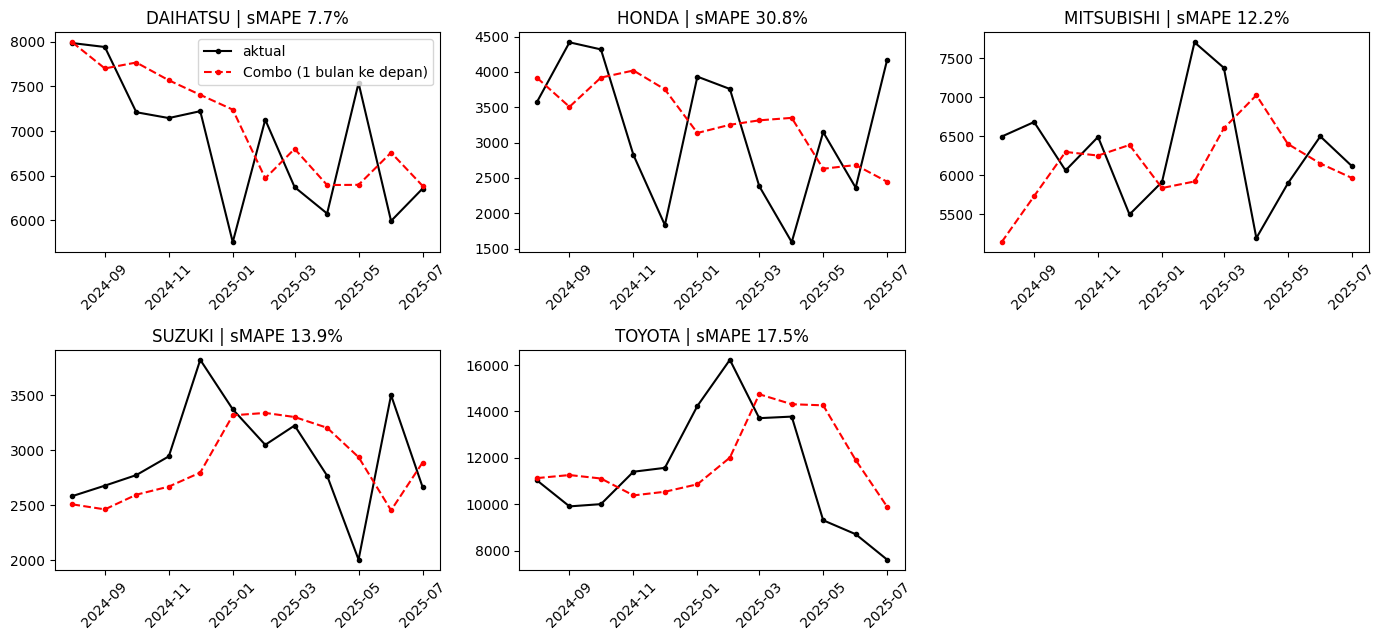

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=False); axes = axes.ravel()
Rc = R[(R.model == 'Combo (MA3+SES+Ridge own)') & (R.periode == 'B')]
for ax, b in zip(axes, BRANDS):
    d = Rc[Rc.brand == b]; ax.plot(d.waktu, d.y, 'k.-', label='aktual'); ax.plot(d.waktu, d.f, 'r.--', label='Combo (1 bulan ke depan)')
    ax.set_title(f'{b} | sMAPE {smape(d.y, d.f):.1f}%'); ax.tick_params(axis='x', rotation=45)
axes[0].legend(); axes[-1].axis('off'); plt.tight_layout(); plt.show()

In [32]:
# Pemeriksaan konsistensi metrik (dihitung ulang dengan cara independen)
def smape_loop(y, f): return 100*sum(2*abs(b - a)/(abs(a) + abs(b)) for a, b in zip(y, f))/len(y)
tab_all = tabel(R)
assert max(abs(smape_loop(d.y.values, d.f.values) - tab_all.loc[m, 'sMAPE']) for m, d in R.groupby('model')) < 0.006, 'sMAPE tidak konsisten'
keys = R.groupby('model').apply(lambda d: tuple(sorted(zip(d.waktu, d.brand))))
assert keys.nunique() == 1 and R.f.notna().all(), 'himpunan prakiraan tidak sama antar model / ada NaN'
ref = sales.stack().rename('y'); yy = R[R.model == 'Naive'].set_index(['waktu', 'brand']).y
assert np.allclose(yy.values, ref.loc[yy.index].values), 'nilai aktual tidak cocok dengan sumber'
print(f'LULUS: sMAPE tabel = hitung ulang independen; {keys.iloc[0].__len__()} pasangan (bulan, merek) identik di {R.model.nunique()} model; aktual cocok dengan data sumber.')

# Angka yang dikutip di narasi bagian 10 harus sama dengan hasil lari ini (toleransi 0,05 poin)
narasi = {'Combo (MA3+SES+Ridge own)': 16.43, 'Ridge pooled: own': 16.58, 'MA3': 16.65, 'Ridge pooled: own+season': 17.06,
          'Ridge pooled: own+ext': 18.89, 'ORACLE Ridge own+ext (eksogen bulan t)': 18.32}
beda = {k: (v, tab_all.loc[k, 'sMAPE']) for k, v in narasi.items() if abs(tab_all.loc[k, 'sMAPE'] - v) > 0.05}
beda_lama = abs(tb.loc['LAMA: LightGBM Optuna + fitur lama', 'sMAPE'] - 16.34) > 0.05
print('Narasi vs hasil:', 'SESUAI' if not beda and not beda_lama else f'PERINGATAN, angka narasi perlu diperbarui: {beda}')
if SAVE_DIR:
    os.makedirs(SAVE_DIR, exist_ok=True)
    tab_all.to_csv(f'{SAVE_DIR}/hasil_gabungan.csv'); tabel(R[R.periode == 'A']).to_csv(f'{SAVE_DIR}/hasil_periode_A.csv')
    tabel(R[R.periode == 'B']).to_csv(f'{SAVE_DIR}/hasil_periode_B.csv'); tb.to_csv(f'{SAVE_DIR}/hasil_periode_B_dengan_lama.csv')
    pm.to_csv(f'{SAVE_DIR}/smape_per_merek.csv'); A_.to_csv(f'{SAVE_DIR}/ablasi.csv')

LULUS: sMAPE tabel = hitung ulang independen; 115 pasangan (bulan, merek) identik di 13 model; aktual cocok dengan data sumber.
Narasi vs hasil: SESUAI


## 8. Prakiraan bulan berikutnya dan kalibrasi interval

**Cara interval 80% dihitung:** untuk model `Combo`, galat log `log(y/f)` dari 115 prakiraan backtest dikumpulkan; kuantil 10% dan 90% (`q10`, `q90`) diterapkan ke prakiraan baru sebagai `f·exp(q)`. Artinya interval bersifat empiris, multiplikatif, dan **sama untuk semua merek**. Kelemahan: galat Honda jauh lebih besar daripada merek lain, kuantil diestimasi dari data yang sama dengan yang dievaluasi, dan galat antar bulan berautokorelasi. Karena itu kalibrasinya diperiksa di bawah, bukan diasumsikan.

In [33]:
COMBO = 'Combo (MA3+SES+Ridge own)'
C = R[R.model == COMBO].reset_index(drop=True); C['lerr'] = np.log(C.y / C.f)
q10, q90 = np.quantile(C.lerr, [0.10, 0.90])

# Prakiraan bulan berikutnya
nxt = sales.index.max() + pd.offsets.MonthBegin(1)
sales_x = sales.reindex(sales.index.append(pd.DatetimeIndex([nxt]))); sales_x.index.name = 'waktu'
fr = pooled_forecast(build_panel(sales_x, bi, ihk), nxt, FEATS['own'], 'ridge')
rows = []
for b in BRANDS:
    h = hist(sales_x, b, nxt); f = np.mean([fc_ma(3)(h), fc_ses(h), fr[b]])
    rows.append((b, f, f*np.exp(q10), f*np.exp(q90)))
fc_tbl = pd.DataFrame(rows, columns=['merek', 'prakiraan', 'P10', 'P90']).set_index('merek').round(0).astype(int)
print(f'Prakiraan {nxt:%b %Y} (Combo), faktor interval 80%: x{np.exp(q10):.2f} s.d. x{np.exp(q90):.2f}'); print(fc_tbl.to_string())
print(f'Total titik 5 merek: {fc_tbl.prakiraan.sum():,} unit (interval total tidak dihitung: menjumlahkan batas per merek tidak valid).')

Prakiraan Aug 2025 (Combo), faktor interval 80%: x0.70 s.d. x1.19
            prakiraan   P10   P90
merek                            
DAIHATSU         6546  4570  7788
HONDA            3302  2305  3928
MITSUBISHI       6112  4267  7272
SUZUKI           2718  1898  3234
TOYOTA           8113  5664  9653
Total titik 5 merek: 26,791 unit (interval total tidak dihitung: menjumlahkan batas per merek tidak valid).


In [34]:
# Kalibrasi: seberapa sering aktual jatuh di dalam interval? (nominal 80%)
def loo_hit(df):   # tiap galat diuji dengan kuantil dari galat lain (leave-one-out)
    return pd.Series([np.quantile(df.drop(index=i).lerr, .1) <= r.lerr <= np.quantile(df.drop(index=i).lerr, .9) for i, r in df.iterrows()], index=df.index)
C['hit_loo'] = loo_hit(C)
cross = {}
for tr, te in [('A', 'B'), ('B', 'A')]:
    a, b_ = np.quantile(C[C.periode == tr].lerr, [.1, .9]); d = C[C.periode == te]; cross[f'kuantil {tr} -> uji {te}'] = ((d.lerr >= a) & (d.lerr <= b_)).mean()*100
cal = pd.DataFrame({'cakupan_LOO_%': C.groupby('brand').hit_loo.mean()*100, 'std_log_galat': C.groupby('brand').lerr.std()}).round(2)
cal.loc['SEMUA'] = [C.hit_loo.mean()*100, C.lerr.std()]
print('Kalibrasi interval 80% (pooled, galat Combo):'); print(cal.round(2).to_string())
print('Lintas periode:', {k: round(v, 1) for k, v in cross.items()})
print('Median log(y/f):', C.groupby('periode').lerr.median().round(3).to_dict(), '(negatif = prakiraan cenderung terlalu tinggi)')
if SAVE_DIR: cal.to_csv(f'{SAVE_DIR}/kalibrasi_interval.csv'); fc_tbl.to_csv(f'{SAVE_DIR}/prakiraan_bulan_berikutnya.csv')

Kalibrasi interval 80% (pooled, galat Combo):
            cakupan_LOO_%  std_log_galat
brand                                   
DAIHATSU            86.96           0.17
HONDA               65.22           0.38
MITSUBISHI          82.61           0.19
SUZUKI              78.26           0.20
TOYOTA              82.61           0.18
SEMUA               79.13           0.24
Lintas periode: {'kuantil A -> uji B': np.float64(73.3), 'kuantil B -> uji A': np.float64(81.8)}
Median log(y/f): {'A': -0.073, 'B': -0.007} (negatif = prakiraan cenderung terlalu tinggi)


**Penilaian kalibrasi (berdasarkan angka di atas):** cakupan keseluruhan mendekati nominal, tetapi **tidak merata**: Honda jauh di bawah 80% (interval terlalu sempit), Daihatsu di atas 80% (terlalu lebar), dan uji lintas periode memberi 73–82%. Kuantil per merek sempat diperiksa dan **lebih buruk** di luar sampel (±23 titik per merek terlalu sedikit), sehingga interval pooled dipertahankan. Perlakukan interval sebagai **indikatif**, terutama untuk Honda.

## 9. Keterbatasan data dan validitas
**Data**
- **Patahan Jan 2024.** Level penjualan empat dari lima merek turun tajam dan format nilai berubah (bulat → pecahan). Kami menangani patahan secara teknis (statistik level dihitung dalam rezim; model pooled memakai rasio terhadap level).
- **Des 2023 hilang.** Deret direindeks agar bulan itu menjadi NaN eksplisit dan jendela lag/rolling tidak melewatinya. Nilai Des 2023 tidak diimputasi.
- **Data berakhir Jul 2025.** Prakiraan "bulan berikutnya" adalah Agu 2025.
- Seluruh rezim 2024–2025 hanya 19 bulan: musiman tahunan tidak bisa diuji bersih.

**Validitas evaluasi**
- Rolling-origin dengan ekspansi jendela, horizon 1 bulan; uji perturbasi (bagian 6) tidak menemukan kebocoran pada model non-oracle. Pengecualian yang disengaja: model *oracle* dan reproduksi pendekatan lama (fitur lama memuat nilai bulan `t`, tetapi modelnya konstan sehingga tidak memengaruhi skor).
- Hiperparameter ditetapkan sebelum eksperimen dan tidak di-tuning, tetapi **±13 varian model dibandingkan pada 23 bulan uji yang sama**; peringkat terbaik dari banyak varian cenderung optimistis. `Combo` ditambahkan setelah putaran pertama.
- Periode uji pendek dan berautokorelasi; selisih di bawah ±0,5 poin sMAPE tidak bermakna.
- Pendekatan lama hanya dapat dievaluasi pada periode B dan memakai periode pelatihan yang berbeda (mulai Jul 2024), sehingga perbandingannya tidak sepenuhnya sebanding.

## 10. Kesimpulan
### Temuan utama
1. **Tidak ada model yang jelas mengalahkan baseline sederhana.** Pada 115 prakiraan (23 bulan × 5 merek), sMAPE terbaik hanya 16,4–16,7% (`Combo`, `Ridge pooled: own`, `MA3`). Selisih `Combo` terhadap `MA3` adalah −0,22 poin ± 0,37 (galat baku antar bulan; menang di 15 dari 23 bulan): tidak dapat dibedakan dari noise.
2. **Fitur eksternal (BI-7DRR dan IHK) tidak membantu.** Dengan model dan hiperparameter yang sama, menambah BI/IHK (tersedia saat prediksi) menaikkan sMAPE dari 16,58% menjadi 18,89%. Varian *oracle* dengan BI/IHK bulan `t` pun tidak membaik (18,32%). Ini **bukan bukti bahwa suku bunga/inflasi tidak berpengaruh**, hanya bahwa data sepanjang ini tidak cukup untuk menunjukkannya.
3. **Fitur musiman dan model boosting juga tidak membantu pada ukuran data ini** (Ridge + musiman 17,06%; LightGBM pooled 17,9–18,3%).
4. **Pendekatan lama setara dengan rata-rata ekspansif.** LightGBM hasil Optuna tidak memakai fitur apa pun (satu pohon, nol split) dan mencapai sMAPE 16,34% pada periode B, hampir sama dengan baseline. Skor 10–30% di notebook lama tidak membuktikan kemampuan model.
5. **Kesulitan berbeda antar merek**: Honda paling sulit (sMAPE 22–30%); merek lain 13–17% pada model unggulan. Prakiraan **total** lima merek lebih akurat (sMAPE `Combo`: 7,6% pada periode B, 9,5% gabungan).

### Rekomendasi model
- Gunakan **`Combo (MA3 + SES + Ridge pooled own)`** sebagai prakiraan utama, dengan **`MA3`** sebagai pembanding transparan. Klaim superioritas **tidak** didukung: keunggulan `Combo` ada dalam noise dan dipilih setelah melihat putaran pertama.